<a href="https://colab.research.google.com/github/auroraguorui-cmyk/llm-learning/blob/main/Karpathy/01_micrograd.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

micrograd

In [1]:
# brew install graphviz
# pip install graphviz
from graphviz import Digraph
def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root, format='svg', rankdir='LR'):
    """
    format: png | svg | ...
    rankdir: TB (top to bottom graph) | LR (left to right)
    """
    assert rankdir in ['LR', 'TB']
    nodes, edges = trace(root)
    dot = Digraph(format=format, graph_attr={'rankdir': rankdir}) #, node_attr={'rankdir': 'TB'})

    for n in nodes:
        dot.node(name=str(id(n)), label = "{ data %.4f | grad %.4f }" % (n._data, n._grad), shape='record')
        if n._op:
            dot.node(name=str(id(n)) + n._op, label=n._op)
            dot.edge(str(id(n)) + n._op, str(id(n)))

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

In [2]:
import math
class Value:
  def __init__(self, data, children = (), op = None):
     self._data = data
     self._prev = children
     self._grad = 0
     self._op = op
     self._backward = lambda: None

  def __add__(self, other):
    if not isinstance(other, Value):
      raise Exception("not Value object")

    def _backward():
      self._grad += out._grad
      other._grad += out._grad

    out = Value(self._data + other._data, children = (self, other), op = '+')
    out._backward = _backward
    return out

  def __sub__(self, other):
    if not isinstance(other, Value):
      raise Exception("not Value object")

    def _backward():
      self._grad += out._grad
      other._grad -= out._grad

    out = Value(self._data - other._data, children = (self, other), op = '-')
    out._backward = _backward
    return out

  def __mul__(self, other):
    if not isinstance(other, Value):
      raise Exception("not Value object")

    def _backward():
      self._grad += out._grad * other._data
      other._grad += out._grad * self._data
    out = Value(self._data * other._data, children = (self, other), op = '*')
    out._backward = _backward
    return out

  def __truediv__(self, other):
    if not isinstance(other, Value):
      raise Exception("not Value object")

    def _backward():
      self._grad += out._grad / other._data
      other._grad -= out._grad * self._data / other._data**2
    out = Value(self._data / other._data, children = (self, other), op = '/')
    out._backward = _backward
    return out

  def __pow__(self, other):
    if not isinstance(other, (int, float)):
      raise Exception("exponent must be a number")

    def _backward():
      self._grad += out._grad * other * self._data**(other-1)
    out = Value(self._data**other, children = (self,), op = '**')
    out._backward = _backward
    return out

  def exp(self):
    def _backward():
      self._grad += out._grad * math.exp(self._data)
    out = Value(math.exp(self._data), children = (self,), op = 'exp')
    out._backward = _backward
    return out

  def tanh(self):
    def _backward():
      self._grad += out._grad * (1 - math.tanh(self._data)**2)

    out = Value(math.tanh(self._data), children = (self,), op = 'tanh')
    out._backward = _backward
    return out

  def backward(self):
    topo = []
    visited = set()
    def build(v):
        if v not in visited:
            visited.add(v)
            for child in v._prev:
                build(child)
            topo.append(v)
    build(self)

    self._grad = 1
    for node in reversed(topo):
        node._backward()


  # def backward(self):
  #   visited = set()
  #   to_visit = [self]
  #   while to_visit:
  #     current = to_visit.p
  #     current._backward()
  #     visited.add(current)
  #     for next in current._prev.items():
  #       if next not in visited:
  #         to_visit.add(next)

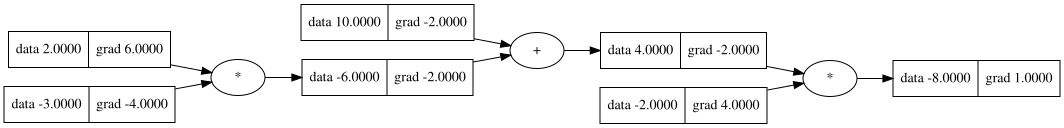

In [3]:
a = Value(2.0)
b = Value(-3.0)
c = Value(10.0)
e = a* b
d = e+ c
f = Value(-2.0)
L = d * f
L.backward()

draw_dot(L)

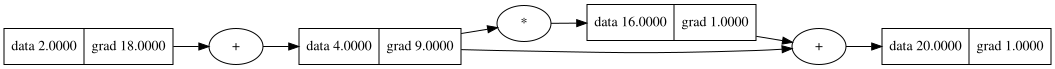

In [4]:
a = Value(2.0)
b = a + a      # b = 4.0
c = b * b      # c = 16.0
d = b + c      # d = 20.0
d.backward()
draw_dot(d)

In [6]:
h = 1e-6
x = Value(5.0); y = x.exp(); y.backward()
print("analytic:", x._grad)
print("numeric:", (math.exp(5.0+h) - math.exp(5.0-h)) / (2*h))

analytic: 148.4131591025766
numeric: 148.41315912406117


In [7]:
# 1. 原始表达式
a = Value(2.0); b = Value(-3.0); c = Value(10.0)
e = a * b; d = e + c; f = Value(-2.0); L = d * f
L.backward()
print(L._grad, a._grad, b._grad, c._grad, d._grad, e._grad, f._grad)
# 期望: 1.0 6.0 -4.0 -2.0 -2.0 -2.0 4.0

# 2. a + a 菱形累加
a2 = Value(2.0); c2 = a2 + a2; c2.backward()
print(a2._grad)  # 期望 2.0

# 3. 分支图（验拓扑排序）
a3 = Value(2.0); b3 = a3 + a3; c3 = b3 * b3; d3 = b3 + c3
d3.backward()
print(a3._grad)  # 期望 18.0（老的前序版本这里会给出 20.0）

1 6.0 -4.0 -2.0 -2.0 -2.0 4.0
2
18.0


**Neuron**

In [8]:
import random
class Neuron:
  def __init__(self, n_in):
    self.w = [Value(random.uniform(-1, 1)) for _ in range(n_in)]
    self.b = Value(0)

  def __call__(self, x):
    x = [v if isinstance(v, Value) else Value(v) for v in x]
    out = self.w[0] * x[0]
    for i in range(1, len(x)):
      out += self.w[i] * x[i]
    out += self.b
    return out.tanh()

  def parameters(self):
    return self.w + [self.b]

class Layer:
  def __init__(self, n_in, n_out):
    self.neurons = [Neuron(n_in) for _ in range(n_out)]

  def __call__(self, x):
    outs = [n(x) for n in self.neurons]
    return outs[0] if len(outs) == 1 else outs

  def parameters(self):
    return [p for n in self.neurons for p in n.parameters()]

class MLP:
  def __init__(self, n_in, n_outs):
    self.layers = [Layer(n_in, n_outs[0])]
    for i in range(1,len(n_outs)):
      self.layers.append(Layer(n_outs[i-1], n_outs[i]))

  def __call__(self, x):
    for layer in self.layers:
      x = layer(x)
    return x

  def parameters(self):
    return [p for layer in self.layers for p in layer.parameters()]

In [9]:
n = Neuron(3)
out = n([2.0, 3.0, -1.0])
out.backward()
print(n.w[0]._grad)

0.006394076638697843


In [10]:
mlp = MLP(3, [4, 4, 1])
out = mlp([2.0, 3.0, -1.0])
print(type(out).__name__, len(mlp.parameters()))

Value 41


In [31]:
xs = [[2.0, 3.0, -1.0], [3.0, -1.0, 0.5], [0.5, 1.0, 1.0], [1.0, 1.0, -1.0]]
ys = [1.0, -1.0, -1.0, 1.0]
model = MLP(3, [4, 4, 1])
lr = 0.2

iter = 0
while True:
  iter += 1
  print('iter ', iter)
  y_preds = [model(xs[0]), model(xs[1]), model(xs[2]), model(xs[3])]
  l1 = (y_preds[0] - Value(ys[0]))**2
  l2 = (y_preds[1] - Value(ys[1]))**2
  l3 = (y_preds[2] - Value(ys[2]))**2
  l4 = (y_preds[3] - Value(ys[3]))**2
  loss = (l1+l2+l3+l4)/Value(4)
  print('loss ', loss._data)
  if loss._data < 0.01 or iter > 100:
    break
  for p in model.parameters():
    p._grad = 0
  loss.backward()
  for p in model.parameters():
    p._data -= lr * p._grad

iter  1
loss  0.2849549503119094
iter  2
loss  0.15751215094908244
iter  3
loss  0.10238810123611691
iter  4
loss  0.07386252050439632
iter  5
loss  0.056441408278152354
iter  6
loss  0.0450246882591
iter  7
loss  0.03710192700693576
iter  8
loss  0.0313465567507962
iter  9
loss  0.027009616714746273
iter  10
loss  0.023642977105701592
iter  11
loss  0.020964923443152355
iter  12
loss  0.018790791328076706
iter  13
loss  0.016995152264618882
iter  14
loss  0.015490180742317583
iter  15
loss  0.014212746045162782
iter  16
loss  0.013116421367388777
iter  17
loss  0.012166374785873511
iter  18
loss  0.011336008519803627
iter  19
loss  0.010604691776119305
iter  20
loss  0.00995619657289003


In [24]:
loss._data > 0.01

False